---
title: "3.5.c Riesgo por incendios y humo"
short_title: "c. Riesgo"
subtitle: "Interfaz urbano-forestal, edificaciones cercanas a focos y exposición al humo"
description: "Exposición de Leticia a incendios de cobertura vegetal en la interfaz urbano-forestal y al humo regional."
keywords: [incendios, interfaz urbano-forestal, humo, exposición, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/35_incendios/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El riesgo por incendios forestales en Leticia tiene dos caras: el **fuego en la interfaz** entre la ciudad y el
bosque o los rastrojos (viviendas de la periferia sobre la vía a Tarapacá), y el **humo**, que afecta a toda la
población cuando arde la región en temporada seca.

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from leticia import aoi, clima, espacial, exposicion, fuentes, riesgo, viz
from leticia.config import parametros

pi = parametros()["incendios"]
urbana = aoi.area_urbana()
mun = fuentes.limite_municipal()


def focos(sensor="modis", anios=None):
    f = fuentes.focos_calor(sensor, anios)
    if sensor == "modis":
        f = f[f["confidence"] >= pi["confianza_modis_min"]]
    else:
        f = f[f["confidence"].astype(str).str.lower().isin(pi["confianza_viirs"])]
    f = f[f["type"] == 0] if "type" in f else f          # solo vegetación (excluye fuentes estáticas y volcanes)
    return gpd.GeoDataFrame(f, geometry=gpd.points_from_xy(f.longitude, f.latitude), crs=4326)

## 1. Interfaz urbano-forestal

In [3]:
wc = fuentes.raster_estatico("esa-worldcover", "map", clave_bbox="bbox_urbano", resolucion=0.0000898)
vegetacion = wc.isin([10, 20, 30])            # árboles, arbustos y pastos (combustible)
pol_veg = espacial.vectorizar(vegetacion.rio.write_crs(4326), 1000).to_crs(aoi.crs())   # parches continuos ≥ ~10 ha
edif = exposicion.edificaciones_urbanas()
pts = edif.representative_point()
d_veg = pts.distance(pol_veg.union_all().boundary)
viirs = focos("viirs-snpp", list(range(2012, 2026))).to_crs(aoi.crs())
from scipy.spatial import cKDTree
arbol = cKDTree(np.column_stack([viirs.geometry.x, viirs.geometry.y])) if len(viirs) else None
d_foco = pd.Series(arbol.query(np.column_stack([pts.x, pts.y]))[0], index=edif.index) if arbol is not None else pd.Series(np.inf, index=edif.index)
edif["interfaz"] = d_veg <= 50
edif["foco_500m"] = d_foco <= pi["bufer_interfaz_m"]
tabla = pd.DataFrame({
    "edificaciones": [int(edif.interfaz.sum()), int(edif.foco_500m.sum()), int((edif.interfaz & edif.foco_500m).sum())],
    "personas": [edif.loc[edif.interfaz, "poblacion"].sum(), edif.loc[edif.foco_500m, "poblacion"].sum(),
                 edif.loc[edif.interfaz & edif.foco_500m, "poblacion"].sum()]},
    index=["a ≤ 50 m de vegetación continua ≥ 10 ha (interfaz)", f"a ≤ {pi['bufer_interfaz_m']} m de un foco VIIRS 2012–2025", "ambas condiciones"])
display(tabla.round(0))

,edificaciones,personas
a ≤ 50 m de vegetación continua ≥ 10 ha (interfaz),3730,"19,855.00"
a ≤ 500 m de un foco VIIRS 2012–2025,516,"1,198.00"
ambas condiciones,308,864.00


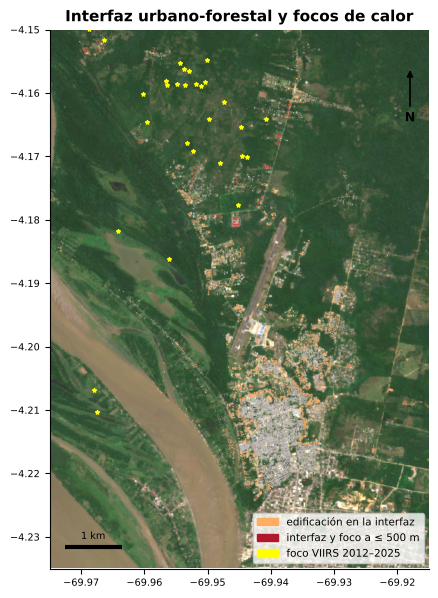

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 7))
viz.fondo(ax)
edif[~edif.interfaz].to_crs(4326).plot(ax=ax, color="#bbbbbb", linewidth=0, zorder=2)
edif[edif.interfaz].to_crs(4326).plot(ax=ax, color="#fdae61", linewidth=0, zorder=3)
edif[edif.interfaz & edif.foco_500m].to_crs(4326).plot(ax=ax, color=viz.ROJO, linewidth=0, zorder=4)
if len(viirs):
    viirs.to_crs(4326).plot(ax=ax, color="yellow", markersize=8, marker="*", zorder=5)
ax.legend(handles=[Patch(color="#fdae61", label="edificación en la interfaz"), Patch(color=viz.ROJO, label="interfaz y foco a ≤ 500 m"),
                   Patch(color="yellow", label="foco VIIRS 2012–2025")], loc="lower right", fontsize=7.5, frameon=True)
viz.marco(ax, titulo="Interfaz urbano-forestal y focos de calor")

In [5]:
viz.pie(viz.nota_fuente("cobertura_suelo", "focos_calor", "edificaciones"))

*Fuente: ESA WorldCover — WorldCover 10 m 2021 v200; NASA FIRMS — Archivo anual por país, MODIS (1 km, 2001–) y VIIRS S-NPP (375 m, 2012–); Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey.*

## 2. Riesgo relativo por celda

,n_edif,poblacion
riesgo_incendio,,
Muy baja,540,"5,535.00"
Baja,1448,"14,608.00"
Media,3121,"22,321.00"
Alta,1143,"2,718.00"
Muy alta,556,"1,325.00"


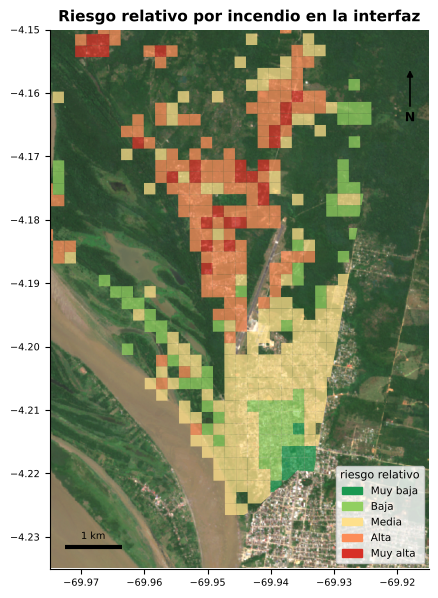

In [6]:
malla = exposicion.malla_exposicion()
g = edif.groupby("id_celda")
malla["frac_interfaz"] = g["interfaz"].mean().reindex(malla.index)
malla["dist_foco_m"] = malla.geometry.centroid.apply(lambda p: arbol.query([p.x, p.y])[0] if arbol is not None else np.inf)
amenaza = 0.5 * riesgo.normalizar(malla["dist_foco_m"], invertir=True) + 0.5 * riesgo.normalizar(malla["frac_interfaz"].fillna(0))
expo = 0.5 * riesgo.normalizar(malla["poblacion"]) + 0.5 * riesgo.normalizar(malla["n_edif"])
malla["riesgo_incendio"] = riesgo.matriz_riesgo(riesgo.clasificar(amenaza), riesgo.clasificar(expo.where(malla.n_edif > 0)))
con = malla[malla.n_edif > 0]
fig, ax = plt.subplots(figsize=(6.4, 7))
viz.mapa_celdas(con, "riesgo_incendio", ax=ax, categorias=riesgo.CLASES, colores=riesgo.COLORES_CLASES, etiqueta="riesgo relativo",
                titulo="Riesgo relativo por incendio en la interfaz")
display(con.groupby("riesgo_incendio", observed=False)[["n_edif", "poblacion"]].sum().round(0))
malla[["frac_interfaz", "dist_foco_m", "riesgo_incendio"]].to_csv(fuentes.ruta("riesgo_incendio_celdas.csv"))

## 3. Humo: un riesgo regional

El humo que llega a Leticia proviene sobre todo de incendios en Brasil, Perú y Bolivia durante las sequías, que el
archivo colombiano de FIRMS no incluye. En la sequía de 2023 los incendios en la Amazonía brasileña aumentaron
52 % en septiembre–octubre frente a agosto y unas 150 000 personas tuvieron problemas de salud asociados al
fuego [@costa2023spa]. Toda la población de Leticia está expuesta en esas temporadas; los más sensibles son los
niños, las personas mayores y quienes tienen enfermedades respiratorias.

**Lectura.** El riesgo directo por fuego se concentra en la periferia, en las viviendas contiguas a rastrojos y
bosques sobre la vía a Tarapacá. Las medidas clave son la **prohibición y control de quemas en temporada seca**,
la vigilancia con alertas de focos (FIRMS, IDEAM), franjas de protección en la interfaz y la conservación del
bosque periurbano. Para el humo: alertas de calidad del aire y protocolos de salud pública en sequías.